# Singular Value Decomposition Tracking Demonstration

This notebook demonstrates the capabilities of `singularpairtrack` for tracking the Singular Value Decomposition (SVD) of a parameter-dependent matrix $A(t)$. Standard SVD algorithms computed at individual time points can exhibit sign flips in the singular vectors (U and V matrices) or inconsistent ordering of singular values when they cross or become close. `eigenpairflow` aims to provide continuous tracking.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from eigenpairflow.tracking import singularpairtrack

# Setup for plotting
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Define a Time-Dependent Matrix A(t)

We construct $A(t) = U(t) \Sigma(t) V(t)^T.

* $\Sigma(t)$ contains singular values that vary smoothly.
* $U(t)$ and $V(t)$ are rotation matrices that rotate with $t$. An example of a rotation matrix is $\begin{pmatrix} \cos \theta & - \sin \theta \\ \sin \theta & \cos \theta \end{pmatrix}$.

In [2]:
def A_func(t):
    # Singular values
    s1 = 1.0 + 0.5 * np.sin(t)
    s2 = 0.5 + 0.3 * np.cos(t)
    S = np.diag([s1, s2])

    # Rotation angle
    theta = 0.5 * t
    c, s = np.cos(theta), np.sin(theta)
    
    # U and V matrices (rotations)
    U = np.array([[c, -s], [s, c]])
    V = np.array([[np.cos(theta/2), -np.sin(theta/2)], 
                  [np.sin(theta/2), np.cos(theta/2)]])

    return U @ S @ V.T

t_eval = np.linspace(0, 2 * np.pi, 200)

## 2. Track SVD using `singularpairtrack`

We use the library function to track the decomposition continuously.

In [3]:
results = singularpairtrack(A_func, t_eval)

print(f"Tracking successful: {results.success}")
print(f"Message: {results.message}")

Tracking successful: True
Message: Ogita-SVD Tracking


## 3. Visualize Results

We plot the singular values and the components of the singular vectors.

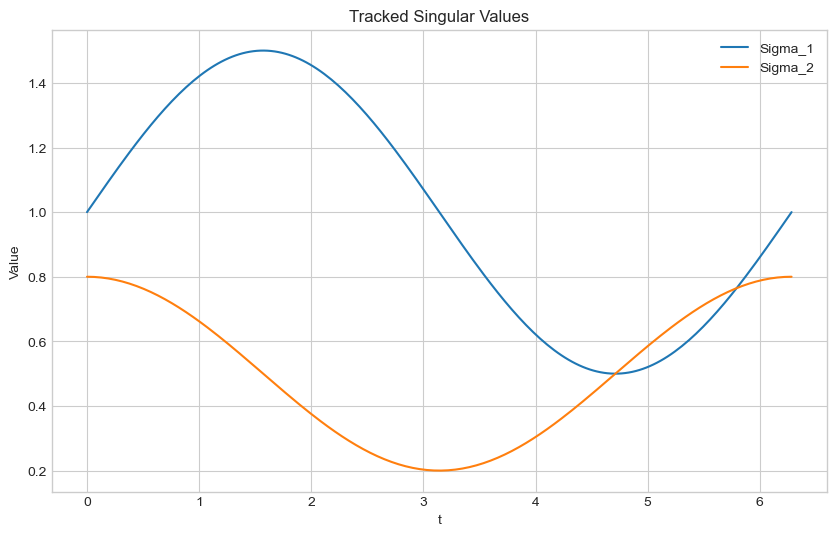

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_eval, results.Ss, label=['Sigma_1', 'Sigma_2'])
ax.set_title('Tracked Singular Values')
ax.set_xlabel('t')
ax.set_ylabel('Value')
ax.legend()
plt.show()

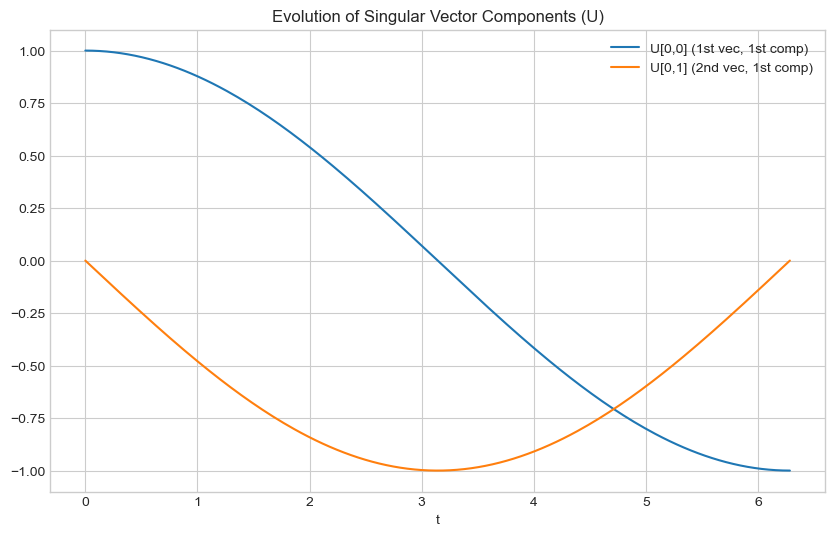

In [5]:
# Plot first component of U vectors
U11 = np.array(results.Us)[:, 0, 0]
U12 = np.array(results.Us)[:, 0, 1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_eval, U11, label='U[0,0] (1st vec, 1st comp)')
ax.plot(t_eval, U12, label='U[0,1] (2nd vec, 1st comp)')
ax.set_title('Evolution of Singular Vector Components (U)')
ax.set_xlabel('t')
ax.legend()
plt.show()

## 4. Check Reconstruction Error

We verify that the tracked decomposition accurately reconstructs the original matrix $A(t)$.

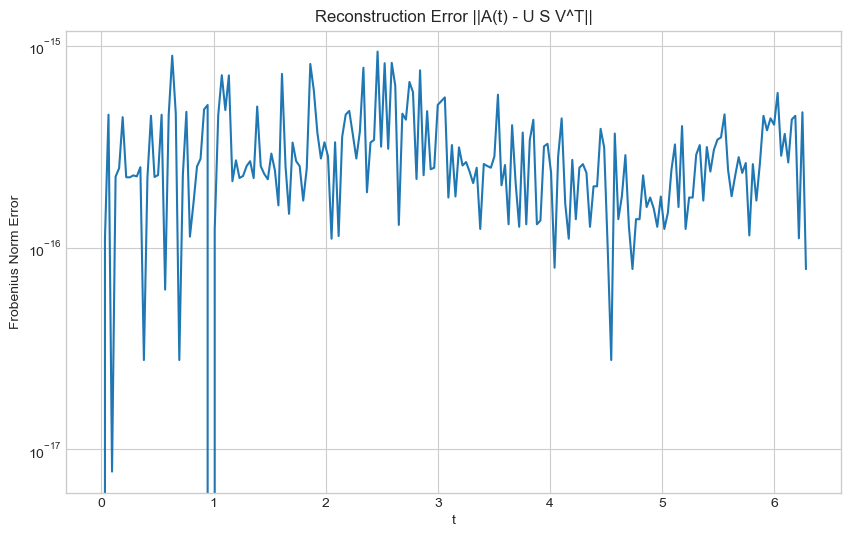

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_eval, results.norm_errors)
ax.set_title('Reconstruction Error ||A(t) - U S V^T||')
ax.set_yscale('log')
ax.set_xlabel('t')
ax.set_ylabel('Frobenius Norm Error')
plt.show()